In [163]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import umap
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import ee
import os
import duckdb

In [164]:
ee.Initialize(project="lucera-494618")

In [116]:
import duckdb

result = duckdb.query("""
    SELECT 
        COUNT(*) as total_points,
        COUNT(DISTINCT label_name) as n_classes
    FROM read_parquet('../data/raw/**/*.parquet')
""").df()

print(result)

   total_points  n_classes
0      45824569         11


In [117]:
sns.set_theme(style="darkgrid")

class_counts = duckdb.query("""
    SELECT 
        label_name,
        COUNT(*) as count
    FROM read_parquet('../data/raw/**/*.parquet')
    WHERE label_name IS NOT NULL
    GROUP BY label_name
    ORDER BY count DESC
""").df()

print(f"Total points: {class_counts['count'].sum():,}")
print(class_counts.to_string(index=False))

Total points: 45,824,569
            label_name    count
            Tree cover 20165439
              Cropland 10698009
             Grassland  9192729
Permanent water bodies  2526965
       Moss and lichen  1498133
Bare/sparse vegetation   498274
              Built-up   479150
          Snow and ice   311570
    Herbaceous wetland   197351
             Shrubland   189007
             Mangroves    67942


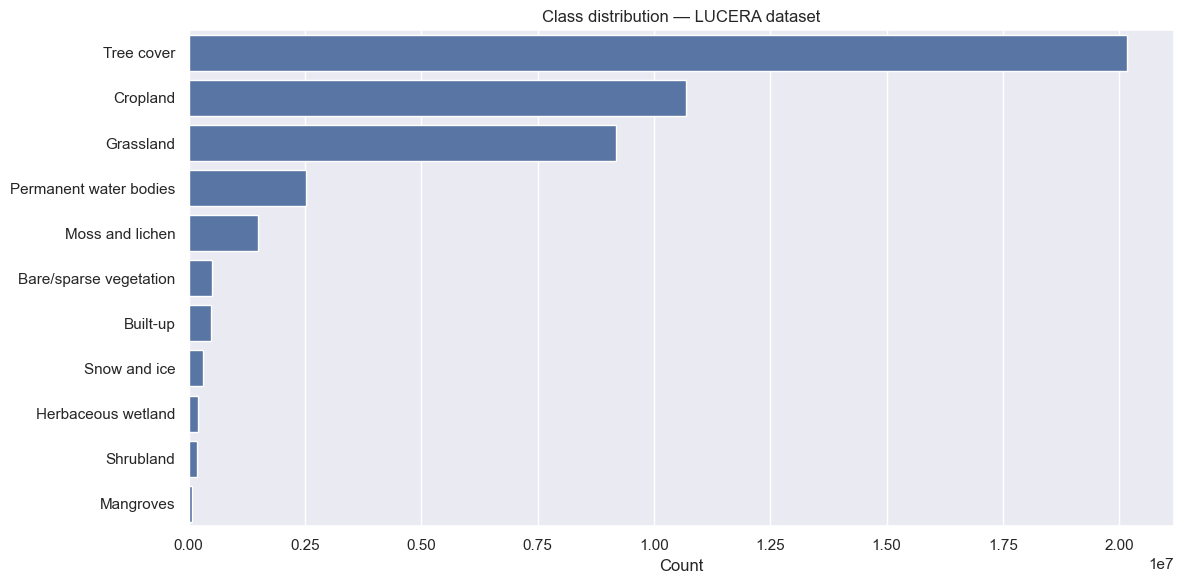

In [118]:
plt.figure(figsize=(12, 6))
sns.barplot(data=class_counts, y='label_name', x='count', order=class_counts['label_name'])
plt.xlabel('Count')
plt.ylabel('')
plt.title('Class distribution — LUCERA dataset')
plt.tight_layout()
plt.show()

In [119]:
df_clean = duckdb.query("""
    SELECT * FROM (
        SELECT *, ROW_NUMBER() OVER (
            PARTITION BY label_name 
            ORDER BY RANDOM()
        ) as rn
        FROM read_parquet('../data/raw/**/*.parquet')
        WHERE label_name IS NOT NULL
    )
    WHERE rn <= 10000
""").df()

print(f"Subsample: {len(df_clean):,} points")
print(df_clean['label_name'].value_counts())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Subsample: 110,000 points
label_name
Mangroves                 10000
Permanent water bodies    10000
Grassland                 10000
Herbaceous wetland        10000
Tree cover                10000
Shrubland                 10000
Built-up                  10000
Bare/sparse vegetation    10000
Cropland                  10000
Moss and lichen           10000
Snow and ice              10000
Name: count, dtype: int64


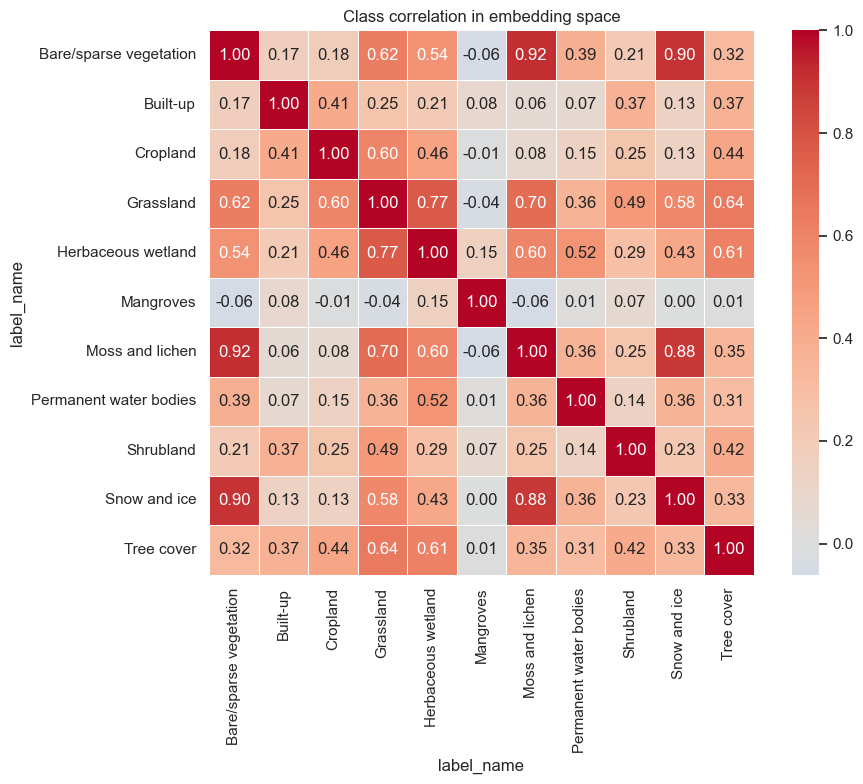

In [120]:
embedding_cols = [c for c in df_clean.columns if c.startswith('A')]

class_means = df_clean.groupby('label_name')[embedding_cols].mean()

corr = class_means.T.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Class correlation in embedding space')
plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

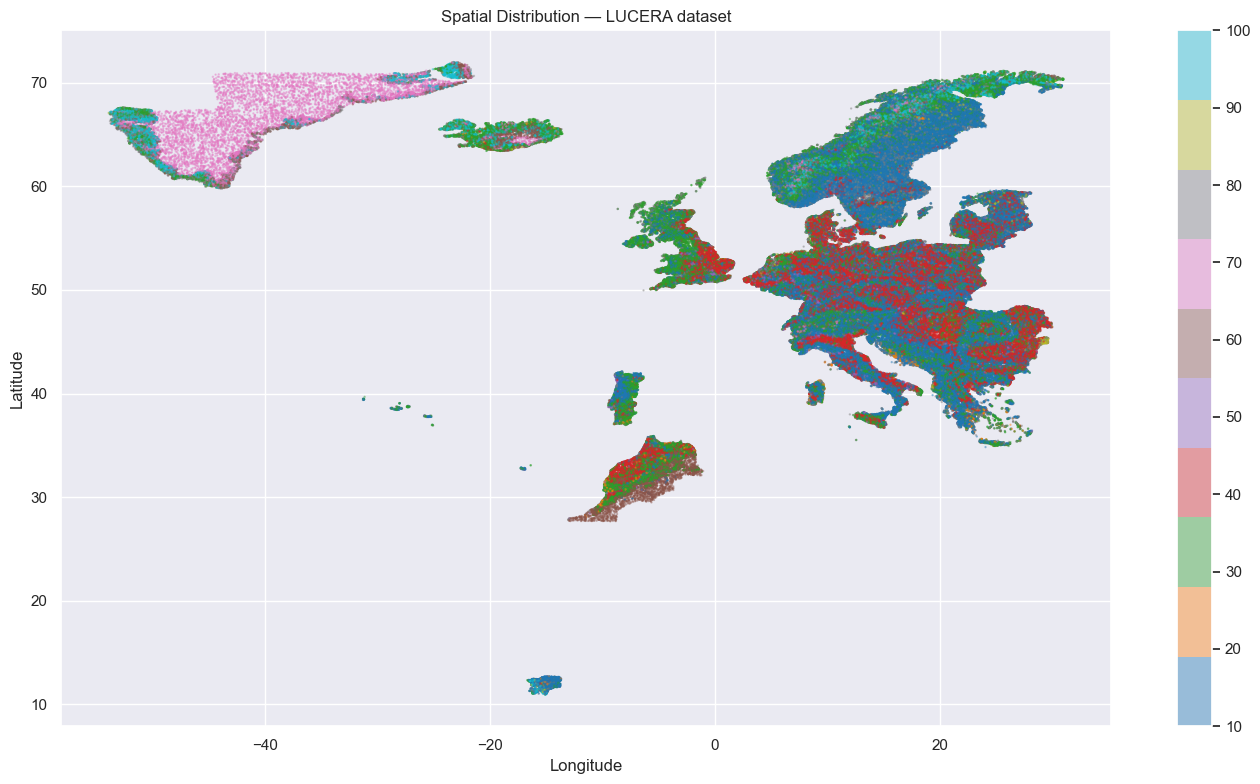

In [190]:
df_sample = duckdb.query("""
    SELECT lat, lon, label
    FROM read_parquet('../data/raw/**/*.parquet')
    USING SAMPLE 400000
""").df()

plt.figure(figsize=(14, 8))
scatter = plt.scatter(
    df_sample['lon'],
    df_sample['lat'],
    c=df_sample['label'],
    cmap='tab10',
    s=0.5,
    alpha=0.4
)
plt.colorbar(scatter)
plt.title('Spatial Distribution — LUCERA dataset')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

label_name
Bare/sparse vegetation    10000
Built-up                  10000
Cropland                  10000
Grassland                 10000
Herbaceous wetland        10000
Mangroves                 10000
Moss and lichen           10000
Permanent water bodies    10000
Shrubland                 10000
Snow and ice              10000
Tree cover                10000
Name: count, dtype: int64
Total: 110000


/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eig

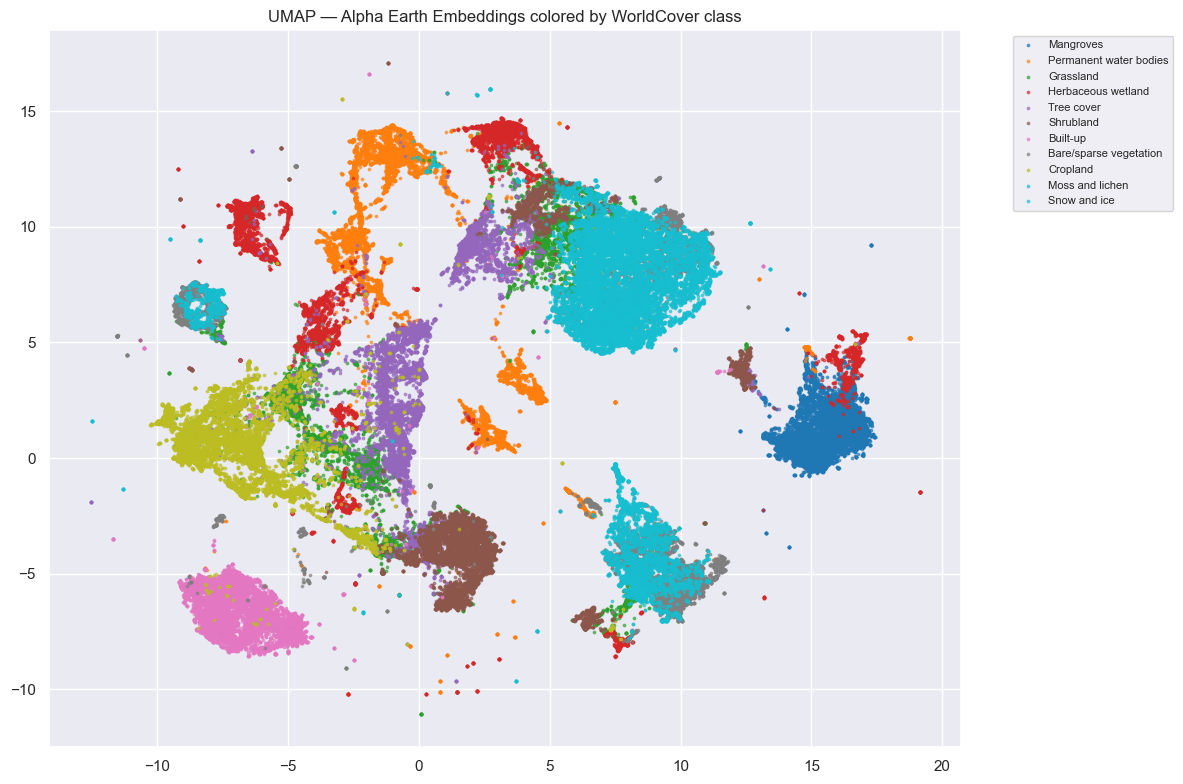

In [122]:
df_sample = df_clean.groupby('label_name', group_keys=False).sample(
    n=10000, replace=True, random_state=42
)

print(df_sample['label_name'].value_counts())
print(f"Total: {len(df_sample)}")

embedding_cols = [c for c in df_sample.columns if c.startswith('A')]
X = df_sample[embedding_cols].values
y = df_sample['label_name'].values

reducer = umap.UMAP(
    random_state=42,
    n_neighbors=15,
    min_dist=0.1,
    low_memory=True
)
embedding_2d = reducer.fit_transform(X)

plt.figure(figsize=(12, 8))
classes = df_clean['label_name'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    mask = y == cls
    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        c=[color],
        label=cls,
        s=3,
        alpha=0.6
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.title('UMAP — Alpha Earth Embeddings colored by WorldCover class')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'PCA — how many dimensions matter?')

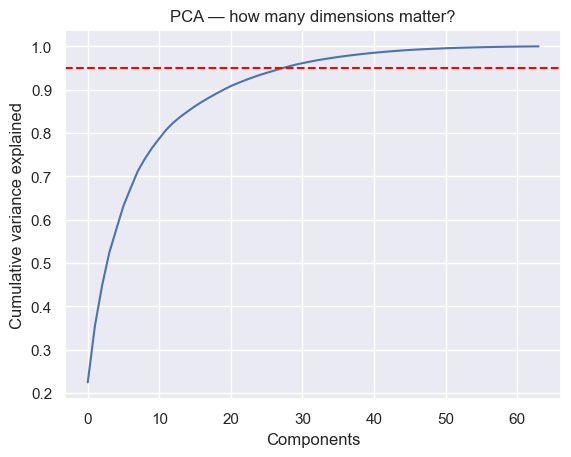

In [123]:
pca = PCA()
pca.fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Components')
plt.ylabel('Cumulative variance explained')
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.title('PCA — how many dimensions matter?')

In [124]:
iso = IsolationForest(contamination=0.02, random_state=42)
outliers = iso.fit_predict(X)
print(f"Outliers detected: {(outliers == -1).sum()}")
df_sample = df_sample[outliers == 1].reset_index(drop=True)

Outliers detected: 2198


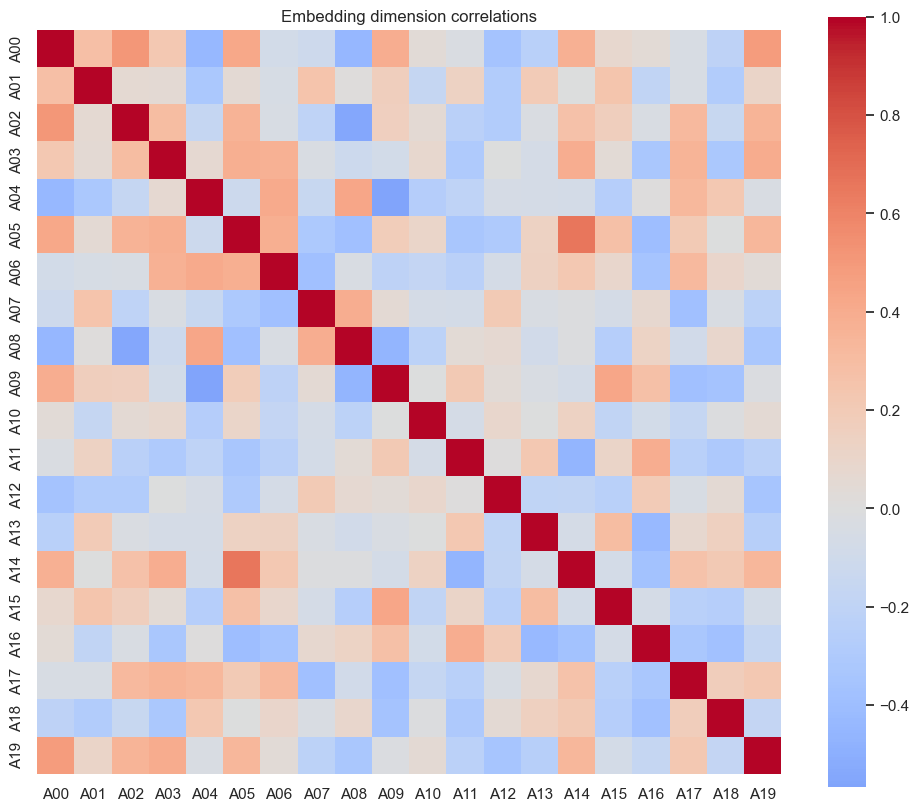

In [125]:
embed_cols = [c for c in df_sample.columns if c.startswith('A')][:20]
X_df = df_sample[embed_cols]
plt.figure(figsize=(12, 10))
sns.heatmap(X_df.corr(), cmap='coolwarm', center=0, square=True)
plt.title('Embedding dimension correlations')
plt.show()

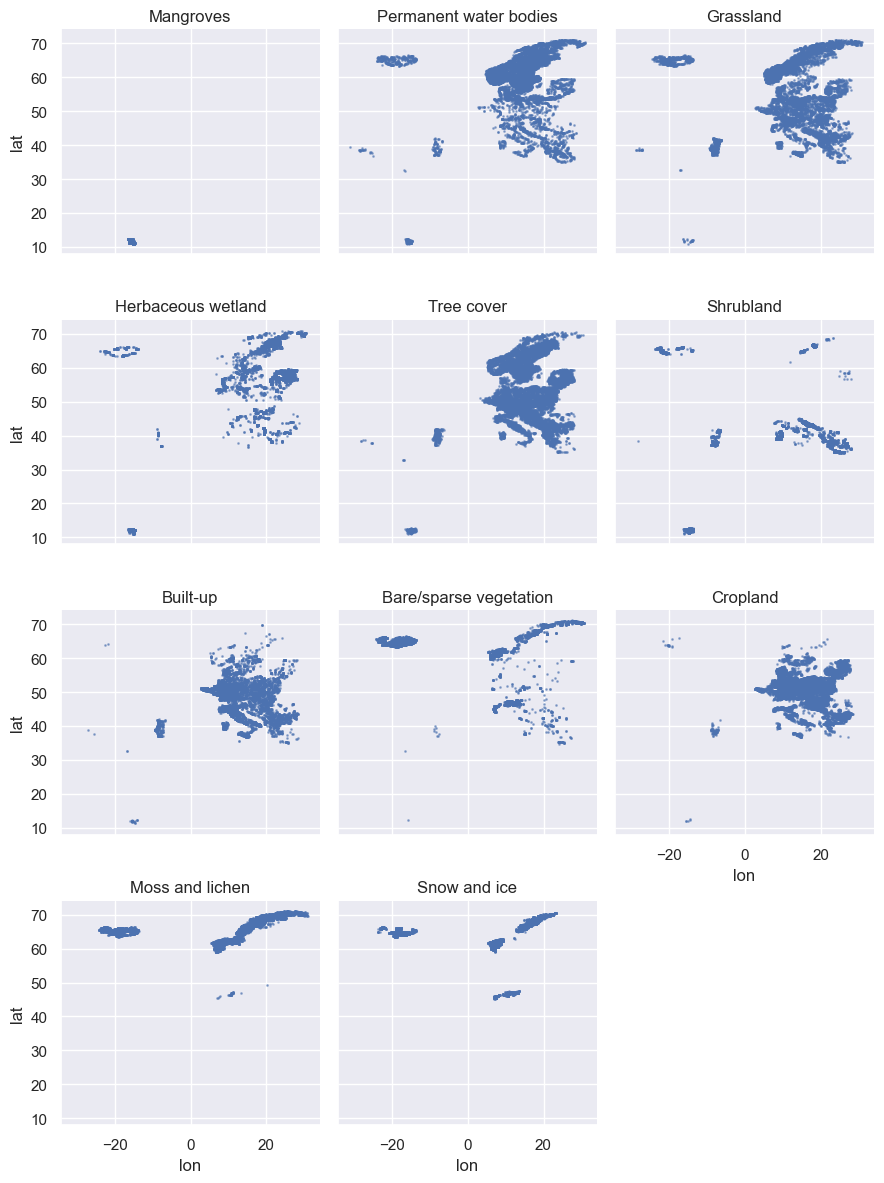

In [126]:
g = sns.FacetGrid(df_clean, col='label_name', col_wrap=3, height=3)
g.map(plt.scatter, 'lon', 'lat', s=1, alpha=0.5)
g.set_titles('{col_name}')
plt.show()

In [127]:
df_clean = duckdb.query("""
    SELECT * FROM (
        SELECT *, ROW_NUMBER() OVER (
            PARTITION BY label_name 
            ORDER BY RANDOM()
        ) as rn
        FROM read_parquet('../data/raw/**/*.parquet', filename=true)
        WHERE label_name IS NOT NULL
        AND NOT contains(filename, '/de/')
    )
    WHERE rn <= 10000
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [128]:
def prepare_ml_dataset(df, min_samples=1000, max_samples=10000, random_state=42):
    """
    Prepare balanced ML-ready dataset from raw embeddings.
    
    Args:
        min_samples: drop classes below this threshold
        max_samples: cap classes above this threshold
        random_state: for reproducibility
    """
    df = df.dropna(subset=['label']).copy()
    
    class_counts = df['label'].value_counts()
    valid = class_counts[class_counts >= min_samples].index
    df = df[df['label'].isin(valid)]
    
    df = df.groupby('label').apply(
        lambda x: x.sample(min(len(x), max_samples), random_state=random_state)
    ).reset_index(drop=True)
    
    print(f"Classes: {df['label_name'].nunique()}")
    print(df['label_name'].value_counts())
    print(f"Total points: {len(df)}")
    
    return df

df_ml = prepare_ml_dataset(df_clean, min_samples=1000, max_samples=10000)

Classes: 11
label_name
Tree cover                10000
Shrubland                 10000
Grassland                 10000
Cropland                  10000
Built-up                  10000
Bare/sparse vegetation    10000
Snow and ice              10000
Permanent water bodies    10000
Herbaceous wetland        10000
Mangroves                 10000
Moss and lichen           10000
Name: count, dtype: int64
Total points: 110000


In [129]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

MIN_SAMPLES = 20

embedding_cols = [c for c in df_ml.columns if c.startswith('A')]
X = df_ml[embedding_cols].values
y = df_ml['label_name'].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Classes: {le.classes_}")

Train: (88000, 64), Test: (22000, 64)
Classes: ['Bare/sparse vegetation' 'Built-up' 'Cropland' 'Grassland'
 'Herbaceous wetland' 'Mangroves' 'Moss and lichen'
 'Permanent water bodies' 'Shrubland' 'Snow and ice' 'Tree cover']


In [130]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, 
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, 
        random_state=42, 
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name} — Test accuracy: {model.score(X_test, y_test):.3f}")
    print(classification_report(y_test, y_pred, target_names=le.classes_))


Logistic Regression — Test accuracy: 0.909
                        precision    recall  f1-score   support

Bare/sparse vegetation       0.83      0.84      0.84      2000
              Built-up       0.99      0.99      0.99      2000
              Cropland       0.93      0.94      0.93      2000
             Grassland       0.80      0.77      0.78      2000
    Herbaceous wetland       0.95      0.95      0.95      2000
             Mangroves       0.98      0.99      0.99      2000
       Moss and lichen       0.84      0.87      0.85      2000
Permanent water bodies       0.97      0.95      0.96      2000
             Shrubland       0.91      0.91      0.91      2000
          Snow and ice       0.88      0.88      0.88      2000
            Tree cover       0.93      0.90      0.92      2000

              accuracy                           0.91     22000
             macro avg       0.91      0.91      0.91     22000
          weighted avg       0.91      0.91      0.91     

In [131]:
df_germany = duckdb.query("""
    SELECT * FROM read_parquet('../data/raw/europe/de/**/*.parquet')
    WHERE label_name IS NOT NULL
    USING SAMPLE 10000
""").df()

print(f"Germany validation: {len(df_germany):,} points")
print(df_germany['label_name'].value_counts())

Germany validation: 10,000 points
label_name
Cropland                  4135
Tree cover                3914
Grassland                 1581
Built-up                   196
Permanent water bodies     166
Bare/sparse vegetation       4
Herbaceous wetland           4
Name: count, dtype: int64


In [132]:
df_val = df_germany.dropna(subset=['label'])
known_classes = le.classes_
df_val = df_val[df_val['label_name'].isin(known_classes)]

embedding_cols = [c for c in df_val.columns if c.startswith('A')]
X_val = df_val[embedding_cols].values
y_val = le.transform(df_val['label_name'].values)

y_pred = models["Random Forest"].predict(X_val)

# only use classes present in validation set
present_classes = sorted(df_val['label_name'].unique())
present_indices = [list(le.classes_).index(c) for c in present_classes]

print(f"Validation accuracy (Germany): {(y_pred == y_val).mean():.3f}")
print(classification_report(
    y_val, y_pred,
    labels=present_indices,
    target_names=present_classes
))

Validation accuracy (Germany): 0.922
                        precision    recall  f1-score   support

Bare/sparse vegetation       0.50      1.00      0.67         4
              Built-up       0.68      0.98      0.80       196
              Cropland       0.92      0.97      0.95      4135
             Grassland       0.84      0.81      0.82      1581
    Herbaceous wetland       0.10      1.00      0.17         4
Permanent water bodies       0.99      0.93      0.96       166
            Tree cover       0.98      0.91      0.95      3914

              accuracy                           0.92     10000
             macro avg       0.71      0.94      0.76     10000
          weighted avg       0.93      0.92      0.92     10000

